In [92]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr

# Фіксація seed для Варіанта 1 (Київ)
np.random.seed(1)
city = "Київ"
monthly_temp = [-4, -3, 2, 9, 15, 19, 21, 20, 14, 8, 2, -2]
months = ["Січ", "Лют", "Бер", "Кві", "Тра", "Чер",
          "Лип", "Сер", "Вер", "Жов", "Лис", "Гру"]

rows = []
for month, temp in zip(months, monthly_temp):
    heating_days = np.clip(18 - temp + np.random.normal(0, 1.5), 0, 30)
    heating_days = round(heating_days)
    cost = 0.15 * heating_days + np.random.normal(0, 1.0)
    cost = round(max(cost, 0), 1)
    rows.append({
        "місто": city, "місяць": month, "температура": temp,
        "опалювальні_дні": heating_days, "витрати_на_опалення": cost,
    })

climate = pd.DataFrame(rows)
print("Перші рядки згенерованого набору:")
display(climate.head())

Перші рядки згенерованого набору:


,місто,місяць,температура,опалювальні_дні,витрати_на_опалення
0,Київ,Січ,-4,24,3.0
1,Київ,Лют,-3,20,1.9
2,Київ,Бер,2,17,0.2
3,Київ,Кві,9,12,1.0
4,Київ,Тра,15,3,0.2


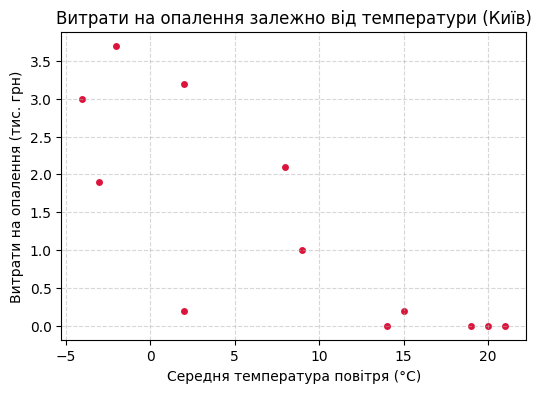

In [93]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(climate["температура"], climate["витрати_на_опалення"], color="crimson", edgecolor="white")
ax.set_xlabel("Середня температура повітря (°C)")
ax.set_ylabel("Витрати на опалення (тис. грн)")
ax.set_title("Витрати на опалення залежно від температури (Київ)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

In [95]:
temp = climate["температура"]
cost = climate["витрати_на_опалення"]

# Коефіцієнт Пірсона
r_res = pearsonr(temp, cost)
# Коефіцієнт Спірмена
rho_res = spearmanr(temp, cost)

print(f"Пірсон: r = {r_res.statistic:.3f}, p-value = {r_res.pvalue:.4e}")
print(f"Спірмен: rho = {rho_res.statistic:.3f}, p-value = {rho_res.pvalue:.4e}")

# 95% довірчий інтервал для r
ci = r_res.confidence_interval(confidence_level=0.95)
print(f"95% довірчий інтервал для Пірсона: ({ci.low:.3f}, {ci.high:.3f})")

Пірсон: r = -0.806, p-value = 1.5285e-03
Спірмен: rho = -0.827, p-value = 9.0770e-04
95% довірчий інтервал для Пірсона: (-0.944, -0.433)


In [96]:
vars_df = climate[["температура", "опалювальні_дні", "витрати_на_опалення"]]

print("Матриця кореляцій Пірсона:")
display(vars_df.corr(method="pearson").round(3))

print("\nМатриця кореляцій Спірмена:")
display(vars_df.corr(method="spearman").round(3))

Матриця кореляцій Пірсона:


,температура,опалювальні_дні,витрати_на_опалення
температура,1.000,-0.987,-0.806
опалювальні_дні,-0.987,1.000,0.787
витрати_на_опалення,-0.806,0.787,1.000



Матриця кореляцій Спірмена:


,температура,опалювальні_дні,витрати_на_опалення
температура,1.000,-0.982,-0.827
опалювальні_дні,-0.982,1.000,0.822
витрати_на_опалення,-0.827,0.822,1.000


In [97]:
# Створюємо копію та додаємо аномальний викид у січні (індекс 0)
climate_outlier = climate.copy()
climate_outlier.loc[0, "витрати_на_опалення"] *= 5.0

# Перераховуємо коефіцієнти з урахуванням викиду
r_out = pearsonr(climate_outlier["температура"], climate_outlier["витрати_на_опалення"])
rho_out = spearmanr(climate_outlier["температура"], climate_outlier["витрати_на_опалення"])

print(f"З викидом - Пірсон r: {r_out.statistic:.3f} (p = {r_out.pvalue:.4e})")
print(f"З викидом - Спірмен rho: {rho_out.statistic:.3f} (p = {rho_out.pvalue:.4e})")

З викидом - Пірсон r: -0.618 (p = 3.2249e-02)
З викидом - Спірмен rho: -0.866 (p = 2.6853e-04)


### Відповіді на контрольні запитання:

1. **Механіка коефіцієнта кореляції Пірсона та діапазон [-1; 1]:**
   - Коефіцієнт Пірсона обчислюється як коваріація двох змінних, поділена на добуток їхніх стандартних відхилень. Ділення на стандартні відхилення стандартизує величину (робить її безрозмірною), а нерівність Коші-Буняковського гарантує, що результат завжди математично потрапляє в діапазон від -1 до 1.

2. **Чому Спірмен рахується на рангах і чому це дає стійкість до викидів:**
   - Коефіцієнт Спірмена переводить початкові числові значення у порядкові рангі. Оскільки викиди отримують просто найбільший чи найменший ранговий номер без урахування їхньої аномально великої чисельної величини, вони не здатні катастрофічно спотворити загальний ранговий розподіл.

3. **Приклад ситуації, де r ≈ 0 при наявності сильного зв'язку:**
   - Класичним прикладом є нелінійний зв'язок, наприклад параболічна залежність ($y = x^2$ в діапазоні $x$ від -2 до 2). Зв'язок ідеально детермінований і сильний, але лінійний коефіцієнт Пірсона дорівнюватиме нулю через симетричну компенсацію додатних і від'ємних гілок параболи.

4. **Чому сильна кореляція не є доказом причинності:**
   - Висока кореляція лише фіксує статистичний зв'язок (синхронність змін), але не вказує напрямок впливу. Причинами можуть бути зворотна причинність, дія прихованого стороннього чинника (конфаундера) або простий випадковий збіг на вибірці.